

# Search-space parameter influence on Nav2 behaviour-tree coverage

Analysis over the six QD (MAP-Elites) campaigns: *which dimensions of the search
space drive behaviour-tree coverage, which dimensions trigger the rare recovery
behaviours, and what higher-level conclusions can be drawn*.

**Perspective on the data.** The 120 parameter sets per campaign were produced by an
optimizer, not by a random sample. MAP-Elites maximises coverage inside every archive
cell, so the *set of evaluated parameters is biased toward high-coverage regions*.
Univariate correlations and even regression importances over all units are therefore
descriptive of *the region QD chose to explore*, not an unbiased estimate of a causal
effect. We mitigate this by (1) reporting marginal curves across the full value range
(QD still *samples* every bin), (2) measuring per-run signal on actual recovery-behaviour
activations, and (3) treating the numbers directionally, not as effect sizes for an
intervention. Everything below is interpretation aid, not an experiment.

For each campaign the QD search space differs (5–7 dimensions):

| campaign | path_length | static obstacle | dynamic obstacle | profile | planner |
|---|---|---|---|---|---|
| nav_through_poses | 3–17 m (SecoroLab) / 2–5 m (hexagon) | – | trigger 0–1 / lateral 0–1 | MPPI/DWB | use_astar |
| nav_to_pose | 3–17 m (SecoroLab) / 2–5 m (hexagon) | amount 0/1, dist 0–1 | trigger 0–1 / lateral 0–1 | MPPI/DWB | use_astar |
| follow_waypoints | 3–17 m (SecoroLab) / 2–5 m (hexagon) | – | trigger 0.75–3 / lateral 0–1 | MPPI/DWB | use_astar |

The search also varies start/goal poses (via `PathVariationRandom`) and warps the
obstacle-spawn trigger point; those latent scenario details are not part of the explicit
search-space dimensions below.


### Setup

In [1]:
from __future__ import annotations
import json, sqlite3, warnings
from pathlib import Path
from xml.etree import ElementTree
from itertools import product

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import cross_val_score, permutation_test_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
try:
    from rosbags.highlevel import AnyReader
    HAVE_ROSBAGS = True
except ImportError:
    HAVE_ROSBAGS = False

DATA_ROOT = Path("/home/sam/Downloads/ICRA analysis")
OPT = DATA_ROOT / "optimization_tests"
CACHE = DATA_ROOT / "bt_coverage_cache"

def _camp_dir(suffix):
    return OPT / f"{suffix}.incomplete" / suffix

CAMPAIGNS = {
    "nav_through_poses_secorolab": _camp_dir("qd-nav-through-poses-secorolab-2026-09-08-01141901"),
    "nav_through_poses_hexagon":   _camp_dir("qd-nav-through-poses-hexagon-2026-09-08-01142436"),
    "nav_to_pose_secorolab":       _camp_dir("qd-nav-to-pose-secorolab-2026-09-08-01140915"),
    "nav_to_pose_hexagon":         _camp_dir("qd-nav-to-pose-hexagon-2026-09-08-01141390"),
    "follow_waypoints_secorolab":  _camp_dir("qd-follow-waypoints-secorolab-2026-09-08-01142971"),
    "follow_waypoints_hexagon":    _camp_dir("qd-follow-waypoints-hexagon-2026-09-08-01143461"),
}
sns.set_theme(style="whitegrid")
mpl.rcParams["figure.dpi"] = 110
warnings.filterwarnings("ignore", category=UserWarning)

for name in CAMPAIGNS:
    assert CAMPAIGNS[name].is_dir(), f"missing campaign dir: {name}"
print("campaigns:", ", ".join(CAMPAIGNS))
print("rosbags importable:", HAVE_ROSBAGS)


/home/sam/.local/lib/python3.12/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sam/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


campaigns: nav_through_poses_secorolab, nav_through_poses_hexagon, nav_to_pose_secorolab, nav_to_pose_hexagon, follow_waypoints_secorolab, follow_waypoints_hexagon
rosbags importable: True


### Load the six campaign databases

In [2]:
def load_campaign(name):
    root = CAMPAIGNS[name]
    conn = sqlite3.connect(root / "campaign.db")
    conn.row_factory = sqlite3.Row
    camp = dict(conn.execute("SELECT * FROM campaign").fetchone())
    units = pd.DataFrame([dict(r) for r in conn.execute(
        "SELECT u.*, b.idx AS batch FROM unit u JOIN batch b ON u.batch_id = b.id "
        "ORDER BY b.idx, u.id")])
    runs = pd.DataFrame([dict(r) for r in conn.execute(
        "SELECT u.config_name, r.run_id, r.status, r.passed, r.duration_s "
        "FROM run r JOIN unit u ON r.unit_id = u.id")])
    conn.close()
    for u in ["params_json", "measures_json", "objectives_json", "channels_json"]:
        units[u] = units[u].apply(lambda s: json.loads(s) if s else None)
    cfg = json.loads(camp["config_json"])
    ss = cfg["search"]["search_space"]
    dim_types = {k: v.get("type") for k, v in ss.items()}
    dims = list(ss.keys())
    bt_xml = cfg["search"]["extract"]["params"]["bt_xml"]
    units["params"] = units["params_json"].apply(
        lambda p: {k: p[k] for k in dims} if p else None)
    for d in dims:
        if dim_types[d] == "choice":
            units[d] = units["params_json"].apply(
                lambda p: ("mppi" if "mppi" in p[d] else "dwb") if p else np.nan)
        else:
            units[d] = units["params_json"].apply(lambda p: p[d] if p else np.nan)
    return dict(name=name, root=root, db=camp, config=cfg, dims=dims,
                dim_types=dim_types, bt_xml=bt_xml,
                description=(cfg.get("metadata") or {}).get("description", ""),
                units=units, runs=runs)

campaigns = {n: load_campaign(n) for n in CAMPAIGNS}
summary = []
for n, c in campaigns.items():
    null_obj = c["units"]["objective"].isna().sum()
    summary.append((n, len(c["units"]), len(c["runs"]), null_obj, ", ".join(c["dims"])))
print(pd.DataFrame(summary, columns=["campaign", "units", "runs", "null_objective", "dims"])
      .to_string(index=False))


                   campaign  units  runs  null_objective                                                                                                                                                               dims
nav_through_poses_secorolab    120   600               0                                                   path_length, dynamic_obstacle_trigger_distance, dynamic_obstacle_lateral_distance, controller_profile, use_astar
  nav_through_poses_hexagon    120   590               2                                                   path_length, dynamic_obstacle_trigger_distance, dynamic_obstacle_lateral_distance, controller_profile, use_astar
      nav_to_pose_secorolab    120   600               1 path_length, static_obstacle_amount, static_obstacle_distance, dynamic_obstacle_trigger_distance, dynamic_obstacle_lateral_distance, controller_profile, use_astar
        nav_to_pose_hexagon    120   600               2 path_length, static_obstacle_amount, static_obstacle_distance, 

### The trees and the coverage denominator

Coverage = (declared BT nodes that left `IDLE` in a run) / (declared nodes). The
declared node set is the flattened BehaviorTree.CPP XML (SubTrees expanded inline).'

In [3]:
def parse_bt_xml(xml_path):
    root = ElementTree.parse(xml_path).getroot()
    trees = {bt.get("ID"): bt for bt in root.iter("BehaviorTree")}
    main_id = root.get("main_tree_to_execute")
    main = trees.get(main_id) if main_id else None
    if main is None:
        main = next(iter(trees.values()), None)
    name_of = lambda el: el.get("name") or el.tag
    names, parents, classes = [], {}, {}

    def walk(el, pid, active):
        nid = len(names)
        names.append(name_of(el)); parents[nid] = pid; classes[nid] = el.tag
        me = nid
        for ch in list(el):
            if ch.tag == "SubTree":
                ref = ch.get("ID"); sub = trees.get(ref)
                if sub is not None and ref not in active:
                    for sc in list(sub):
                        walk(sc, me, active | {ref})
                continue
            walk(ch, me, active)

    for ch in list(main):
        walk(ch, None, frozenset({main_id} if main_id else set()))
    return dict(names=names, parents=parents, classes=classes)

trees = {}
for n, c in campaigns.items():
    xml = c["root"] / "_config" / c["bt_xml"]
    t = parse_bt_xml(xml)
    t["declared"] = set(t["names"])
    t["xml_path"] = xml
    trees[n] = t
    print(f"{n:32s} {c['bt_xml']:48s} declared={len(t['declared']):2d}")


nav_through_poses_secorolab      files/navigate_through_poses_w_replanning_and_recovery.xml declared=24
nav_through_poses_hexagon        files/navigate_through_poses_w_replanning_and_recovery.xml declared=24
nav_to_pose_secorolab            files/navigate_to_pose_w_replanning_and_recovery.xml declared=22
nav_to_pose_hexagon              files/navigate_to_pose_w_replanning_and_recovery.xml declared=22
follow_waypoints_secorolab       files/navigate_to_pose_w_replanning_and_recovery.xml declared=22
follow_waypoints_hexagon         files/navigate_to_pose_w_replanning_and_recovery.xml declared=22


### Per-run data: coverage and node activations

Reuse the validated `bt_coverage_cache/*_reached.json` (bag → `{node: last
non-IDLE status}`). For every bagged run we derive coverage and the set of activated
nodes, then join the unit's search-space parameters by `config_name`. The same
cross-check as the sibling notebook is applied: the mean of the bag-derived run
coverage must reproduce the DB `objective` exactly.

In [4]:
def load_reached(name):
    cache_path = CACHE / f"{name}_reached.json"
    if cache_path.exists():
        return json.loads(cache_path.read_text())
    if not HAVE_ROSBAGS:
        raise RuntimeError(f"no cache and rosbags unavailable for {name}")
    print(f"recomputing reached-node traces for {name} from bags ...")
    out = {}
    root = campaigns[name]["root"]
    for cfg in sorted(d for d in root.iterdir() if d.is_dir() and d.name.startswith("c")):
        for sub in sorted((d.name for d in cfg.iterdir() if d.is_dir() and d.name.isdigit()), key=int):
            bag = cfg / sub / "rosbag2"
            if not bag.is_dir():
                continue
            reached = {}
            with AnyReader([bag]) as reader:
                for conn, _ts, raw in reader.messages(
                        connections=[c for c in reader.connections
                                     if c.topic == "/behavior_tree_log"]):
                    msg = reader.deserialize(raw, conn.msgtype)
                    for ev in msg.event_log:
                        if ev.current_status and ev.current_status != "IDLE":
                            reached[ev.node_name] = ev.current_status
            out[str(bag)] = reached
    return out

def per_run_frame(name):
    camp, tree = campaigns[name], trees[name]
    reached = load_reached(name)
    den = len(tree["declared"])
    rows = []
    for bag, rm in reached.items():
        p = Path(bag)
        covered = set(rm) & tree["declared"]
        rows.append({"config_name": p.parents[1].name, "run_id": int(p.parent.name),
                     "coverage": len(covered) / den, "n_reached": len(covered),
                     "reached": covered})
    runs = pd.DataFrame(rows)
    meta = camp["units"][["config_name", "batch", "objective", *camp["dims"]]]
    runs = runs.merge(meta, on="config_name", how="left")
    return runs, tree["declared"]

analysis = {n: per_run_frame(n) for n in CAMPAIGNS}
for n in CAMPAIGNS:
    r, den = analysis[n]
    print(f"{n:32s} bagged runs={len(r):4d}  denominator={len(den)}")


nav_through_poses_secorolab      bagged runs= 599  denominator=24
nav_through_poses_hexagon        bagged runs= 589  denominator=24
nav_to_pose_secorolab            bagged runs= 595  denominator=22
nav_to_pose_hexagon              bagged runs= 590  denominator=22
follow_waypoints_secorolab       bagged runs= 585  denominator=22
follow_waypoints_hexagon         bagged runs= 425  denominator=22


In [5]:
# Cross-check: bag-derived mean coverage == stored objective (per unit)
bad = 0
for n in CAMPAIGNS:
    r, _ = analysis[n]
    g = r.groupby("config_name")["coverage"].mean().rename("recomputed")
    j = campaigns[n]["units"].set_index("config_name")[["objective"]].join(g)
    j = j[j["objective"].notna()]
    d = (j["recomputed"] - j["objective"]).abs().max()
    bad += int((j["recomputed"] - j["objective"]).abs().gt(1e-9).sum())
    print(f"{n:32s} max|recomputed - db| = {d:.2e}")
print("units deviating > 1e-9:", bad)
assert bad == 0


nav_through_poses_secorolab      max|recomputed - db| = 2.22e-16
nav_through_poses_hexagon        max|recomputed - db| = 0.00e+00
nav_to_pose_secorolab            max|recomputed - db| = 2.22e-16
nav_to_pose_hexagon              max|recomputed - db| = 1.11e-16
follow_waypoints_secorolab       max|recomputed - db| = 2.22e-16
follow_waypoints_hexagon         max|recomputed - db| = 2.22e-16
units deviating > 1e-9: 0



## 1. Influence of each search-space dimension on total coverage

Start univariate: Spearman correlation for the continuous dimensions, level means for
the categorical ones (controller profile, A* on/off, static obstacle present/absent),
computed per campaign on *unit-level* objectives (drop units with `None`). High |ρ| or a
large level gap = the dimension separates low- and high-coverage regions.


In [6]:
NUMERIC = ["path_length", "dynamic_obstacle_trigger_distance",
           "dynamic_obstacle_lateral_distance", "static_obstacle_distance"]
CAT = ["controller_profile", "use_astar", "static_obstacle_amount"]

unit_objs = []
for n, c in campaigns.items():
    u = c["units"].copy()
    u = u[u["objective"].notna()]
    u["campaign"] = n
    unit_objs.append(u)
units = pd.concat(unit_objs, ignore_index=True)

spear = []
for n, c in campaigns.items():
    u = units[units.campaign == n]
    for d in NUMERIC:
        if d in u and u[d].notna().sum() >= 15 and u[d].nunique() > 3:
            rho = spearmanr(u[d], u["objective"]).statistic
            spear.append({"campaign": n, "dim": d,
                          "n": len(u), "spearman_rho": round(rho, 3)})
spearf = pd.DataFrame(spear).pivot(index="campaign", columns="dim", values="spearman_rho")
print("Spearman rho (unit objective) — blank = dimension absent / near-constant")
print(spearf.to_string())

print("\nLevel means of coverage (unit objective)")
for d in CAT:
    levels = pd.DataFrame(
        [{"campaign": n, "dim": d, "level": str(k), "mean_cov": g["objective"].mean(),
          "n": len(g)}
         for n, u in units.groupby("campaign") for k, g in u.groupby(d)])
    print(f"\n-- {d} --")
    print(levels.pivot(index="campaign", columns="level", values="mean_cov")
          .round(3).to_string())


Spearman rho (unit objective) — blank = dimension absent / near-constant
dim                          dynamic_obstacle_lateral_distance  dynamic_obstacle_trigger_distance  path_length  static_obstacle_distance
campaign                                                                                                                                
follow_waypoints_hexagon                                -0.330                              0.160        0.021                       NaN
follow_waypoints_secorolab                              -0.153                              0.285        0.218                       NaN
nav_through_poses_hexagon                               -0.038                              0.097        0.120                       NaN
nav_through_poses_secorolab                             -0.118                              0.065       -0.226                       NaN
nav_to_pose_hexagon                                      0.296                              0.214        

### Marginal coverage curves (per dimension, per campaign)

Equal-width bins per continuous dimension; mean unit coverage per bin with a bootstrap
interval. This shows *shape* (linear, threshold, U-shape) that a correlation hides.

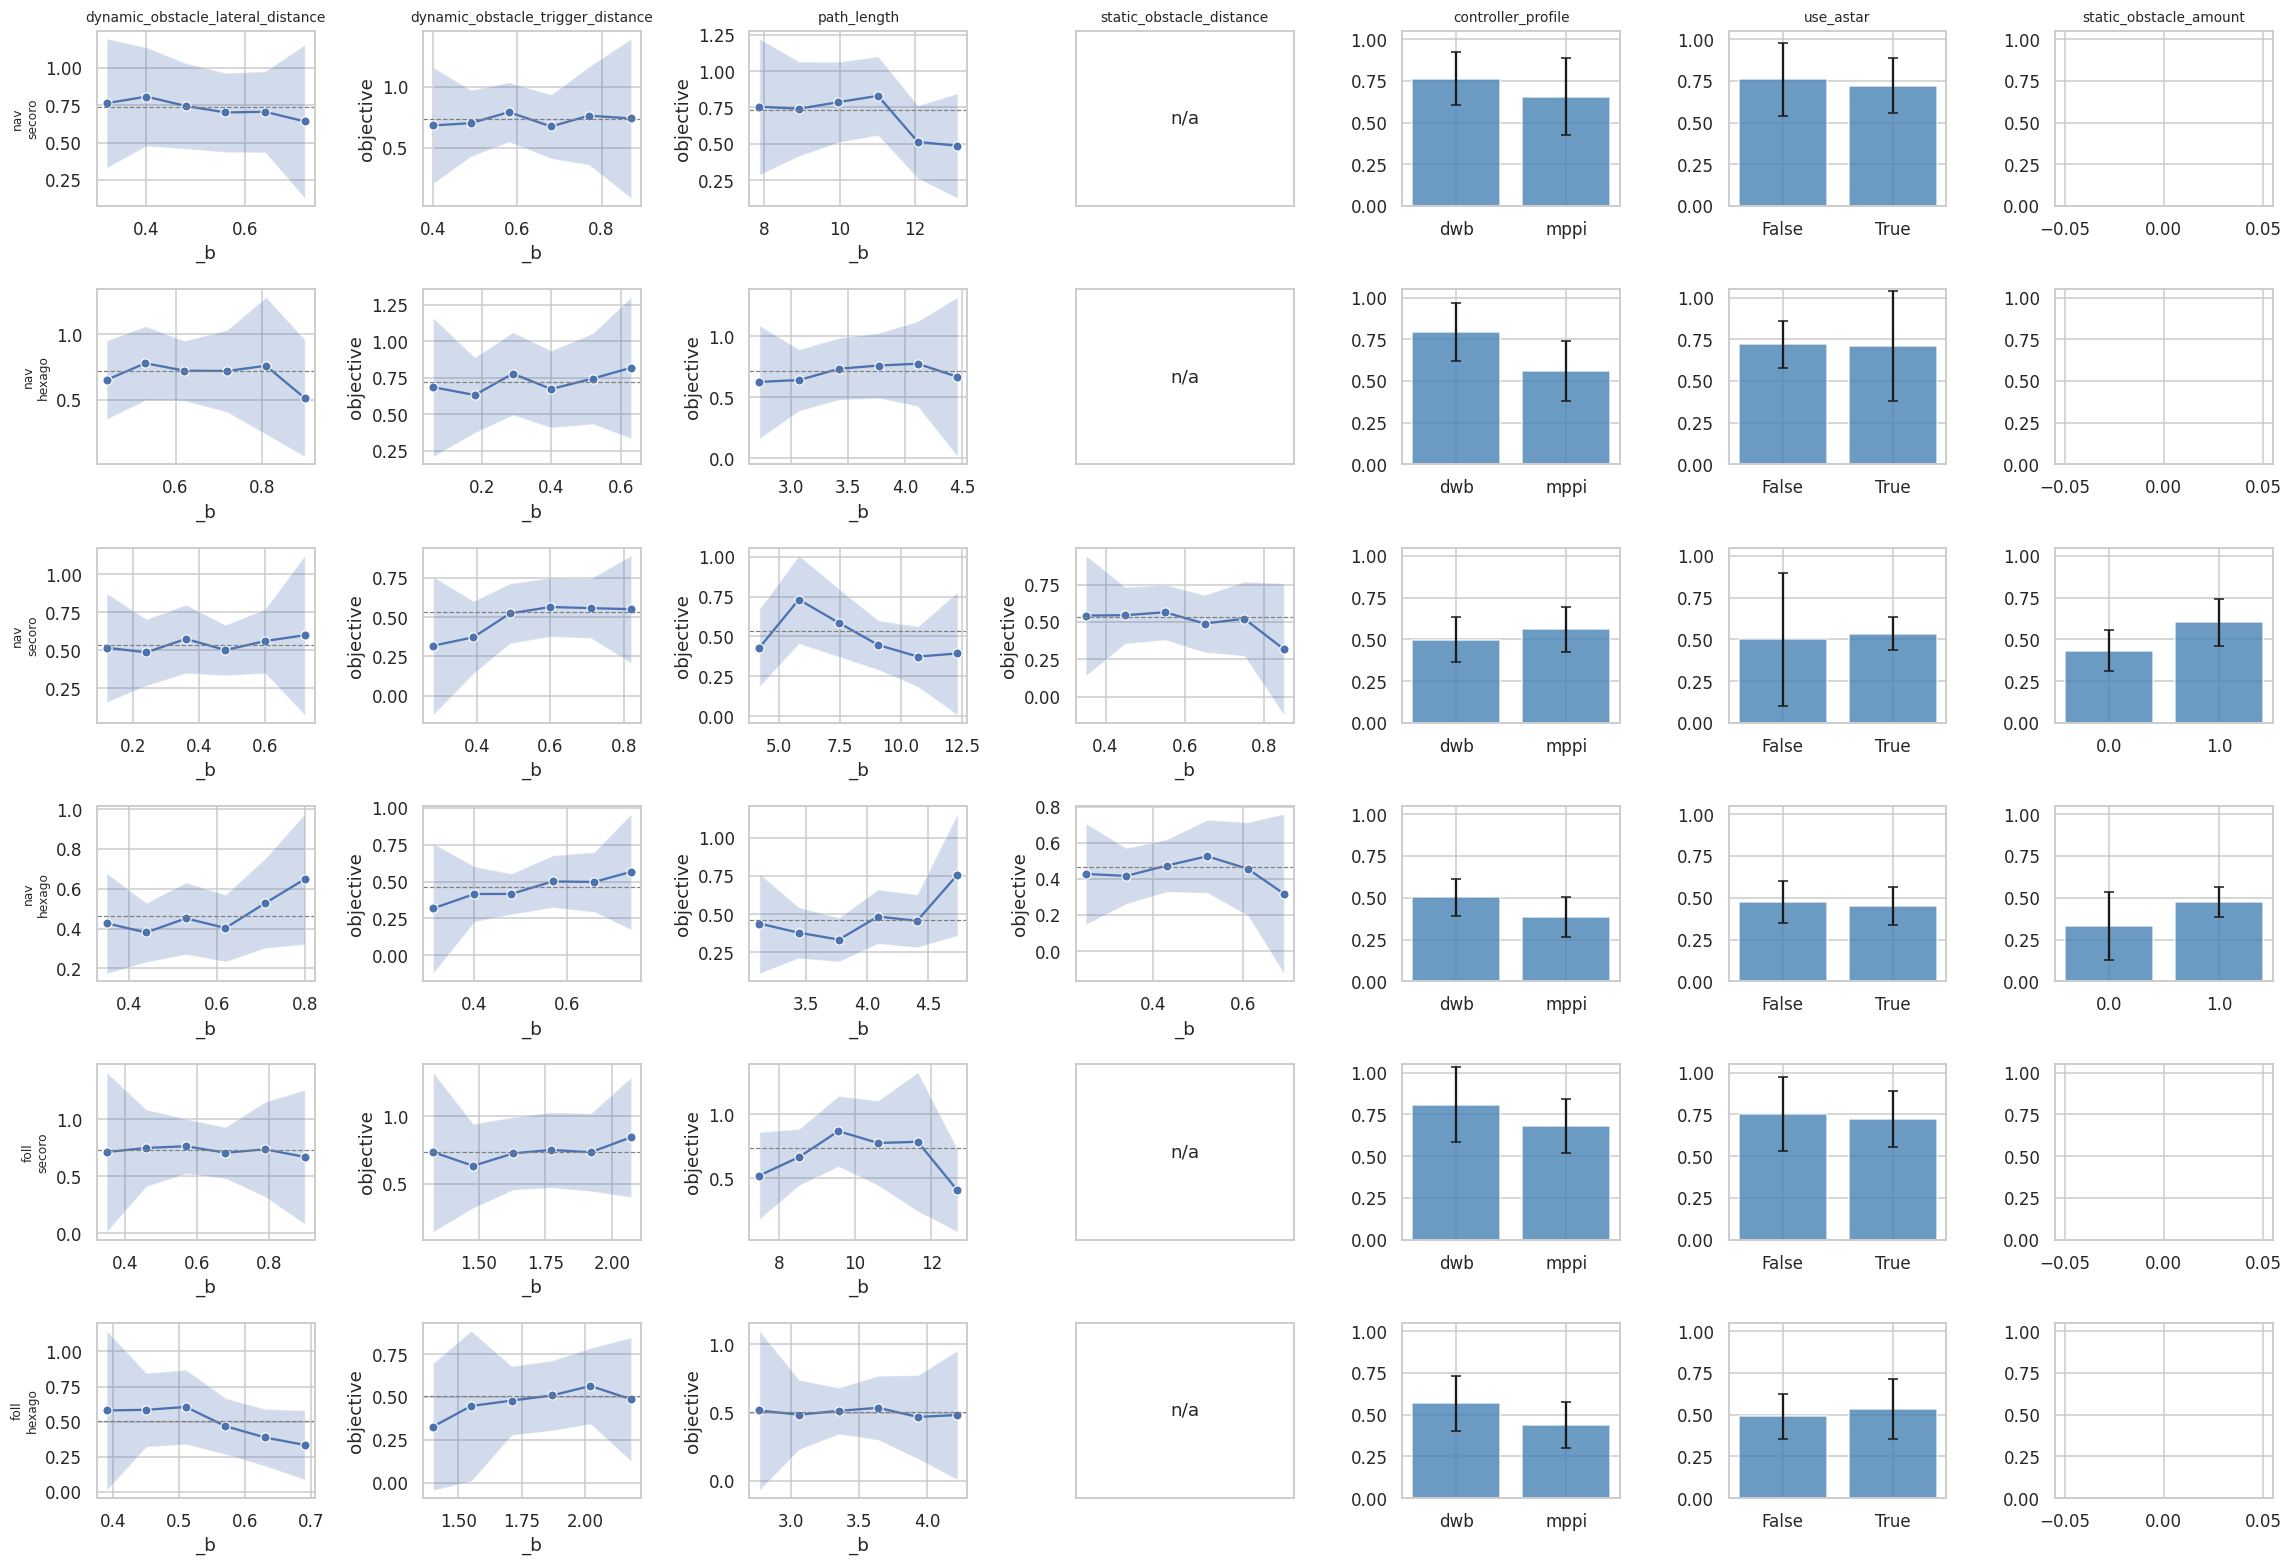

In [7]:
def marginal_rows(u, dim, nbins=6):
    u = u[u[dim].notna()]
    if len(u) < 12 or u[dim].nunique() < 3:
        return None
    lo, hi = u[dim].min(), u[dim].max()
    if lo == hi:
        return None
    bins = np.linspace(lo, hi, nbins + 1)
    lab = [f"{0.5*(bins[i]+bins[i+1]):.2f}" for i in range(nbins)]
    u = u.assign(_b=pd.cut(u[dim], bins=bins, labels=lab, include_lowest=True))
    g = u.dropna(subset=["_b"]).groupby("_b", observed=True)["objective"]
    return {"dim": dim, "x": g.mean().index.astype(float),
            "y": g.mean(), "n": g.count()}

dims_present = sorted({d for c in campaigns.values() for d in c["dims"]
                       if d in NUMERIC})
nrow, ncol = len(CAMPAIGNS), len(dims_present) + len(CAT)
fig, axs = plt.subplots(nrow, ncol, figsize=(3.0 * ncol, 2.4 * nrow), squeeze=False)
for i, n in enumerate(CAMPAIGNS):
    u = units[units.campaign == n]
    for j, d in enumerate(dims_present):
        ax = axs[i, j]
        m = marginal_rows(u, d)
        if m is None:
            ax.text(.5, .5, "n/a", ha="center", va="center", transform=ax.transAxes)
            ax.set_xticks([]); ax.set_yticks([])
        else:
            sns.lineplot(x=m["x"], y=m["y"], marker="o", ax=ax)
            ax.fill_between(m["x"], m["y"] - 1.96 * m["y"] / np.sqrt(m["n"]),
                            m["y"] + 1.96 * m["y"] / np.sqrt(m["n"]), alpha=.25)
            ax.axhline(u.objective.mean(), color="grey", ls="--", lw=.8)
        if i == 0:
            ax.set_title(d, fontsize=9)
        if j == 0:
            ax.set_ylabel(n.split("_")[0][:4] + "\n" + n.split("_")[-1][:6], fontsize=8)
    for j, d in enumerate(CAT, start=len(dims_present)):
        ax = axs[i, j]
        if d not in u:
            ax.text(.5, .5, "n/a", ha="center", va="center", transform=ax.transAxes)
            ax.set_xticks([]); ax.set_yticks([])
            continue
        g = u.groupby(d)["objective"].agg(["mean", "count"])
        xl = g.index.astype(str)
        ax.bar(xl, g["mean"], color="steelblue", alpha=.8)
        ax.errorbar(xl, g["mean"], yerr=1.96 * g["mean"] / np.sqrt(g["count"]),
                    fmt="none", color="k", capsize=3)
        if i == 0:
            ax.set_title(d, fontsize=9)
        ax.set_ylim(0, 1.05)
fig.tight_layout()
plt.show()



## 2. Multivariate influence: how much does each dimension matter together?

A random forest regressor (unit objective) with permutation importance — a guarded,
non-linear extension of the univariate view. Reported per campaign with a
cross-validated R² and a held-out R², so the reader can see how much variance is
explicable at all, then a pooled model across all six campaigns.

In [8]:
def compile_features(df, dims):
    X = pd.DataFrame(index=df.index)
    for d in dims:
        if d == "controller_profile":
            X["profile_mppi"] = df[d].map({"mppi": 1, "dwb": 0})
        elif d == "use_astar":
            X["use_astar"] = df[d].astype(float)
        elif df[d].dtype.kind in "if":
            X[d] = df[d].astype(float)
    return X.dropna(axis=1, how="all").fillna(0.0)

def rf_reg(df, dims, y="objective"):
    X = compile_features(df, dims)
    yv = df[y].astype(float)
    keep = X.notna().all(axis=1) & yv.notna()
    X, yv = X[keep], yv[keep]
    if len(X) < 20 or len(X.columns) == 0:
        return None
    rng = np.random.RandomState(0)
    idx = rng.permutation(len(yv))
    cut = int(0.7 * len(yv))
    tr, te = idx[:cut], idx[cut:]
    model = RandomForestRegressor(n_estimators=300, random_state=0, min_samples_leaf=2)
    model.fit(X.iloc[tr], yv.iloc[tr])
    cv_r2 = cross_val_score(model, X, yv, cv=3, scoring="r2").mean()
    te_r2 = model.score(X.iloc[te], yv.iloc[te])
    perm = permutation_importance(model, X.iloc[te], yv.iloc[te], n_repeats=20,
                                  random_state=0, scoring="r2")
    imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
    return dict(cv_r2=cv_r2, test_r2=te_r2, n=len(yv), importance=imp, model=model, X=X)

rf_results = {}
for n in CAMPAIGNS:
    u = campaigns[n]["units"].copy()
    r = rf_reg(u, campaigns[n]["dims"])
    rf_results[n] = r
    if r:
        top = ", ".join(f"{i}={v:.3f}" for i, v in r["importance"].head(4).items())
        print(f"{n:32s} cvR2={r['cv_r2']:.3f} testR2={r['test_r2']:.3f} n={r['n']:3d}  "
              f"top: {top}")


nav_through_poses_secorolab      cvR2=0.418 testR2=0.438 n=120  top: path_length=0.929, profile_mppi=0.007, use_astar=0.005, dynamic_obstacle_trigger_distance=-0.011
nav_through_poses_hexagon        cvR2=0.741 testR2=0.873 n=118  top: profile_mppi=1.825, path_length=1.716, use_astar=0.000, dynamic_obstacle_trigger_distance=-0.001
nav_to_pose_secorolab            cvR2=0.160 testR2=0.214 n=119  top: path_length=0.433, static_obstacle_amount=0.293, dynamic_obstacle_lateral_distance=0.014, use_astar=0.007
nav_to_pose_hexagon              cvR2=0.206 testR2=0.267 n=118  top: path_length=0.567, profile_mppi=0.042, static_obstacle_distance=0.011, use_astar=0.006
follow_waypoints_secorolab       cvR2=0.040 testR2=0.205 n=117  top: path_length=0.318, dynamic_obstacle_lateral_distance=0.093, dynamic_obstacle_trigger_distance=0.074, profile_mppi=0.037
follow_waypoints_hexagon         cvR2=0.015 testR2=-0.056 n= 85  top: dynamic_obstacle_lateral_distance=0.256, path_length=-0.006, dynamic_obstacle_

In [9]:
# pooled model: all campaigns, campaign one-hot, common dims + pose-specific static dims
ALL_DIMS = [d for n in CAMPAIGNS for d in campaigns[n]["dims"]]
common = sorted({d for d in ALL_DIMS if d in campaigns["nav_to_pose_secorolab"]["dims"]
                 and d in campaigns["follow_waypoints_secorolab"]["dims"]
                 and d in campaigns["nav_through_poses_secorolab"]["dims"]})
pose_extra = ["static_obstacle_amount", "static_obstacle_distance"]
pool = units.copy()
for d in common + pose_extra:
    if d not in pool:
        pool[d] = np.nan
for m, n in enumerate(CAMPAIGNS):
    pool.loc[pool.campaign == n, "_camp"] = m
Xp = compile_features(pool, common + pose_extra)
Xp["campaign"] = pool["_camp"].astype(float)
yv = pool["objective"].astype(float)
keep = Xp.notna().all(axis=1) & yv.notna()
Xp, yv = Xp[keep], yv[keep]
rng = np.random.RandomState(0)
idx = rng.permutation(len(yv)); cut = int(0.7 * len(yv))
tr, te = idx[:cut], idx[cut:]
model = RandomForestRegressor(n_estimators=400, random_state=0, min_samples_leaf=2)
model.fit(Xp.iloc[tr], yv.iloc[tr])
perm = permutation_importance(model, Xp.iloc[te], yv.iloc[te], n_repeats=20, random_state=0)
imp = pd.Series(perm.importances_mean, index=Xp.columns).sort_values(ascending=False)
from sklearn.model_selection import KFold, GroupKFold
cv_shuf = cross_val_score(model, Xp, yv, scoring="r2",
                          cv=KFold(3, shuffle=True, random_state=1)).mean()
cv_holdout = cross_val_score(model, Xp, yv, scoring="r2", cv=GroupKFold(n_splits=3),
                             groups=Xp["campaign"].astype(int).values).mean()
print(f"pooled: cvR2(shuffled)={cv_shuf:.3f}  cvR2(campaign-holdout)={cv_holdout:.3f}  "
      f"testR2={model.score(Xp.iloc[te], yv.iloc[te]):.3f}  n={len(yv)}")
print(imp.to_string(float_format=lambda v: f"{v:.4f}"))


pooled: cvR2(shuffled)=0.466  cvR2(campaign-holdout)=-0.355  testR2=0.481  n=677
path_length                         0.5121
static_obstacle_distance            0.3622
profile_mppi                        0.3323
campaign                            0.1407
static_obstacle_amount              0.0283
dynamic_obstacle_lateral_distance   0.0193
dynamic_obstacle_trigger_distance   0.0114
use_astar                           0.0036



## 3. Which dimensions *trigger the rare behaviours*?

The point of the metric is that the recovery actions — `BackUp`, `Spin`, `Wait`, the
`Clear*Costmap` actions and their gating conditions — fire only in exceptional
situations. For each such behaviour we measure, per run, whether it activated and then
ask which search-space dimensions separate the runs where it did from the runs where it
did not:

* continuous dimensions → AUC of the parameter as a single-feature classifier
  (AUC − 0.5 signed, so +means larger parameter values ⇔ behaviour more likely);
* categorical dimensions → activation rate per level.

Rare target nodes are those reached in a minority of a campaign's runs (but covered at
76 least once), restricted to the recovery subtree so bookkeeping composite nodes such as
`Sequence`/`Fallback` are not mistaken for behaviours.

In [10]:
RARE_BEHAVIOURS = ["BackUp", "Spin", "Wait",
                   "ClearGlobalCostmap-Context", "ClearGlobalCostmap-Subtree",
                   "ClearLocalCostmap-Context", "ClearLocalCostmap-Subtree",
                   "WouldAControllerRecoveryHelp", "WouldAPlannerRecoveryHelp",
                   "ClearingActions", "RecoveryActions", "RecoveryFallback"]
COMPOSITE = {"Sequence", "Fallback", "ReactiveSequence", "RateController",
             "NavigateRecovery", "NavigateWithReplanning", "RecoveryFallback",
             "RecoveryActions", "ClearingActions", "ControllerSelector",
             "PlannerSelector", "GoalUpdated", "RemovePassedGoals"}

rate_rows = []
for n in CAMPAIGNS:
    r, den = analysis[n]
    nrun = len(r)
    for node in RARE_BEHAVIOURS:
        hit = r["reached"].apply(lambda s: node in s)
        fr = hit.mean()
        if fr > 0 and fr < 0.99:
            rate_rows.append({"campaign": n, "node": node, "reach_rate": fr,
                              "in_tree": node in den, "n_runs": nrun})
rare = pd.DataFrame(rate_rows)
rare_pivot = rare.pivot(index="campaign", columns="node", values="reach_rate")
print(rare_pivot.round(3).fillna("·").to_string())


node                         BackUp ClearGlobalCostmap-Context  ClearGlobalCostmap-Subtree  ClearLocalCostmap-Context  ClearLocalCostmap-Subtree  ClearingActions  RecoveryActions  RecoveryFallback   Spin   Wait  WouldAControllerRecoveryHelp WouldAPlannerRecoveryHelp
campaign                                                                                                                                                                                                                                                                  
follow_waypoints_hexagon      0.259                      0.071                       0.289                      0.365                      0.289            0.289            0.289             0.289  0.280  0.273                         0.384                     0.087
follow_waypoints_secorolab    0.427                      0.462                       0.677                      0.535                      0.677            0.677            0.677             0.677  0

In [11]:
# single-feature discriminative power of each dimension for each rare behaviour
disc_rows = []
for n in CAMPAIGNS:
    r, den = analysis[n]
    dims = campaigns[n]["dims"]
    for node in [x for x in RARE_BEHAVIOURS if (rare.campaign == n).any()]:
        sub = r[["run_id", "reached"] + dims].copy()
        y = sub["reached"].apply(lambda s: 1 if node in s else 0)
        fr = y.mean()
        if fr == 0 or fr == 1:
            continue
        for d in dims:
            x = sub[d]
            if x.dtype.kind in "if" and x.nunique() > 3:
                try:
                    auc = roc_auc_score(y, x)
                except ValueError:
                    continue
                disc_rows.append({"campaign": n, "node": node, "dim": d,
                                  "score": (auc - 0.5), "kind": "auc"})
            elif d == "controller_profile":
                m = sub[y == 1][d].value_counts(normalize=True).to_dict()
                disc_rows.append({"campaign": n, "node": node, "dim": d,
                                  "score": m.get("mppi", 0) - m.get("dwb", 0),
                                  "kind": "rate_gap"})
            elif d == "use_astar":
                m = sub[y == 1][d].apply(bool).value_counts(normalize=True).to_dict()
                disc_rows.append({"campaign": n, "node": node, "dim": d,
                                  "score": m.get(True, 0) - m.get(False, 0),
                                  "kind": "rate_gap"})

disc = pd.DataFrame(disc_rows)
# mean across campaigns per (node, dim); AUC scores are on [-0.5, 0.5]
aucp = disc[disc.kind == "auc"].groupby(["node", "dim"])["score"].mean().unstack()
print("AUC-0.5 (positive = larger value => behaviour more likely), mean over campaigns")
print(aucp.reindex([x for x in RARE_BEHAVIOURS if x in aucp.index])
      .round(3).fillna(0).to_string())


AUC-0.5 (positive = larger value => behaviour more likely), mean over campaigns
dim                           dynamic_obstacle_lateral_distance  dynamic_obstacle_trigger_distance  path_length  static_obstacle_distance
node                                                                                                                                     
BackUp                                                   -0.031                              0.094        0.030                     0.002
Spin                                                     -0.021                              0.081        0.035                    -0.010
Wait                                                     -0.031                              0.092        0.031                    -0.015
ClearGlobalCostmap-Context                               -0.068                              0.083       -0.070                    -0.054
ClearGlobalCostmap-Subtree                               -0.023                             

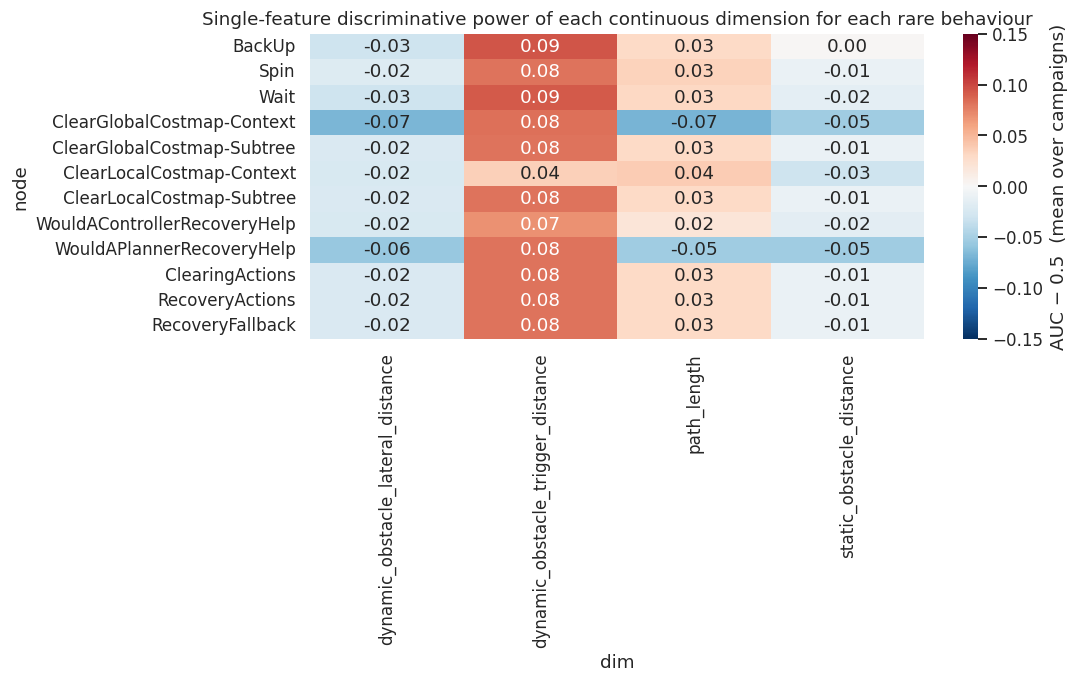

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.6))
auc_sel = aucp.reindex([x for x in RARE_BEHAVIOURS if x in aucp.index]).dropna(axis=1, how="all")
sns.heatmap(auc_sel.fillna(0), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-0.15, vmax=0.15, ax=ax,
            cbar_kws={"label": "AUC \u2212 0.5  (mean over campaigns)"})
ax.set_title("Single-feature discriminative power of each continuous dimension for each rare behaviour")
plt.tight_layout()
plt.show()

In [13]:
# categorical: reached-rate gap per level, aggregated over campaigns
rategap = disc[disc.kind == "rate_gap"].groupby(["node", "dim"])["score"].mean().unstack()
print("\nrate gap (level 'on' minus 'off') — positive => activating the option helps")
print(rategap.reindex([x for x in RARE_BEHAVIOURS if x in rategap.index])
      .round(3).fillna(0).to_string())



rate gap (level 'on' minus 'off') — positive => activating the option helps
dim                           controller_profile  use_astar
node                                                       
BackUp                                    -0.423      0.072
Spin                                      -0.348      0.062
Wait                                      -0.422      0.061
ClearGlobalCostmap-Context                -0.103      0.531
ClearGlobalCostmap-Subtree                -0.344      0.065
ClearLocalCostmap-Context                 -0.511      0.006
ClearLocalCostmap-Subtree                 -0.344      0.065
WouldAControllerRecoveryHelp              -0.354      0.043
WouldAPlannerRecoveryHelp                 -0.131      0.533
ClearingActions                           -0.344      0.065
RecoveryActions                           -0.344      0.065
RecoveryFallback                          -0.344      0.065


### Random-forest ranking per rare behaviour (pooled)

Pool all runs of all campaigns, one-hot-encode the campaign, and fit one classifier per
rare behaviour; permutation importance shows which *combination-aware* dimensions move
the probability of activating that behaviour most.

In [14]:
run_pool = []
for n in CAMPAIGNS:
    r, _ = analysis[n]
    for node in RARE_BEHAVIOURS:
        r[node] = r["reached"].apply(lambda s: 1 if node in s else 0)
    r["_camp"] = n
    run_pool.append(r)
rp = pd.concat(run_pool, ignore_index=True)
for d in common + pose_extra:
    if d not in rp:
        rp[d] = np.nan
Xr = compile_features(rp, common + pose_extra)
Xr = Xr.assign(campaign=rp["_camp"].astype("category").cat.codes)

cls_rows = []
for node in RARE_BEHAVIOURS:
    y = rp[node]
    if len(y.unique()) == 2 and y.mean() > 0.01:
        model = RandomForestClassifier(n_estimators=300, random_state=0,
                                       min_samples_leaf=2, class_weight="balanced")
        model.fit(Xr, y)
        perm = permutation_importance(model, Xr, y, n_repeats=15, random_state=0,
                                      scoring="roc_auc")
        imp = pd.Series(perm.importances_mean, index=Xr.columns).sort_values(ascending=False)
        cls_rows.append((node, y.mean(), imp))
        print(f"{node:32s} rate={y.mean():.3f}  top: "
              + ", ".join(f"{i}={v:.3f}" for i, v in imp.head(4).items()))


BackUp                           rate=0.386  top: path_length=0.142, profile_mppi=0.122, dynamic_obstacle_trigger_distance=0.046, campaign=0.036
Spin                             rate=0.457  top: path_length=0.185, profile_mppi=0.092, campaign=0.041, dynamic_obstacle_trigger_distance=0.036
Wait                             rate=0.397  top: path_length=0.140, profile_mppi=0.127, dynamic_obstacle_trigger_distance=0.047, campaign=0.038
ClearGlobalCostmap-Context       rate=0.187  top: path_length=0.184, use_astar=0.046, dynamic_obstacle_trigger_distance=0.042, profile_mppi=0.014
ClearGlobalCostmap-Subtree       rate=0.473  top: path_length=0.185, profile_mppi=0.096, campaign=0.039, dynamic_obstacle_trigger_distance=0.039
ClearLocalCostmap-Context        rate=0.455  top: profile_mppi=0.132, path_length=0.102, campaign=0.045, dynamic_obstacle_lateral_distance=0.042
ClearLocalCostmap-Subtree        rate=0.473  top: path_length=0.185, profile_mppi=0.096, campaign=0.039, dynamic_obstacle_trigger

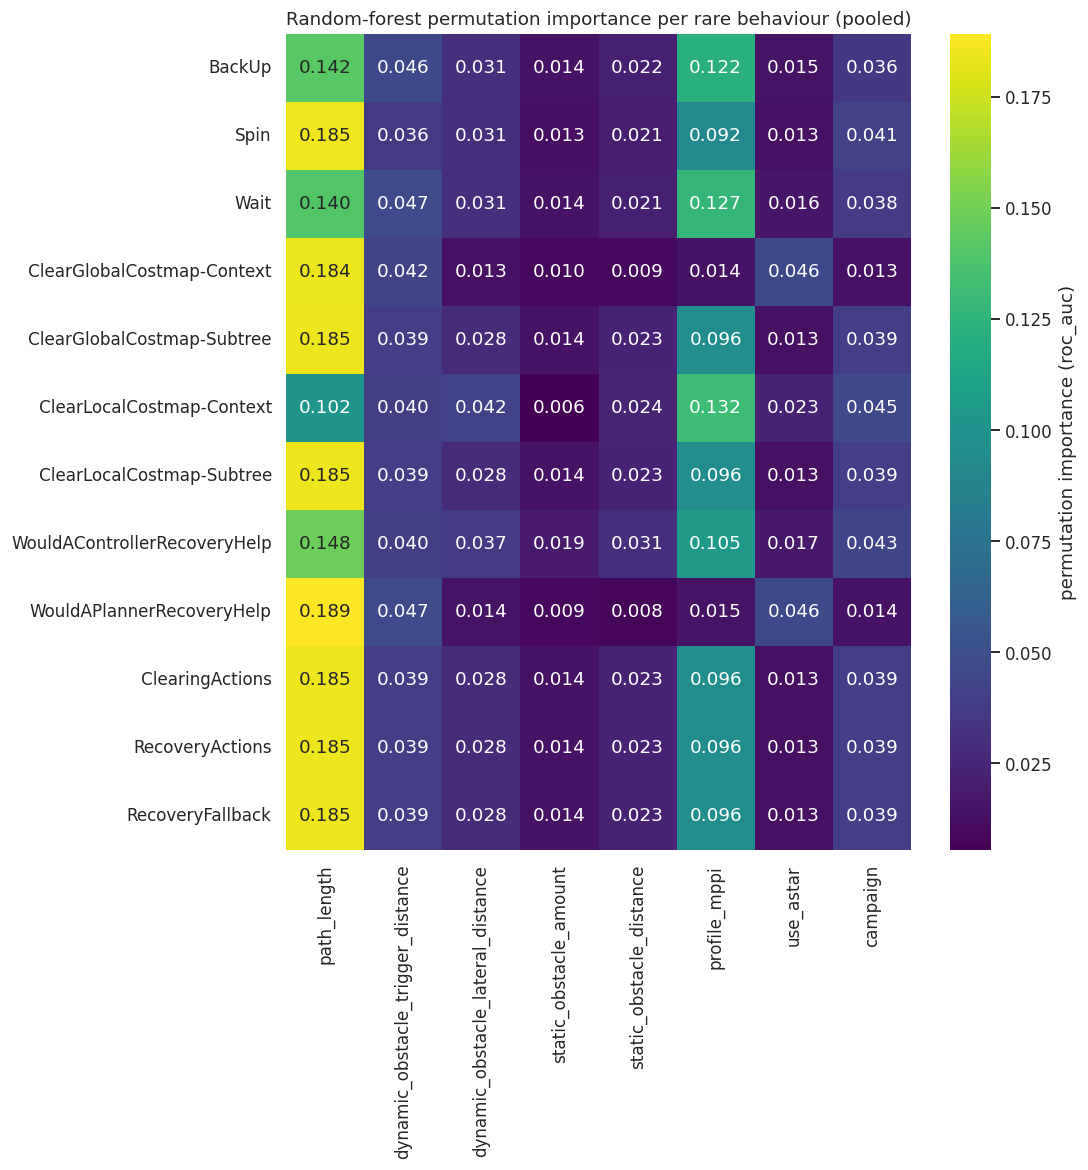

Read: the action family (StackUp/Spin/Wait/ClearLocal*) is driven by path_length + controller profile, the planner-recovery gate (WouldAPlannerRecoveryHelp, ClearGlobalCostmap-Context) is driven by use_astar.


In [15]:
impdf = pd.DataFrame({node: imp for node, _r, imp in cls_rows}).T
feat_order = [f for f in ("path_length", "dynamic_obstacle_trigger_distance",
                          "dynamic_obstacle_lateral_distance", "static_obstacle_amount",
                          "static_obstacle_distance", "profile_mppi", "use_astar",
                          "campaign") if f in impdf.columns]
impdf = impdf[feat_order]
fig, ax = plt.subplots(figsize=(10, 0.9 * len(impdf)))
sns.heatmap(impdf, annot=True, fmt=".3f", cmap="viridis", ax=ax,
            cbar_kws={"label": "permutation importance (roc_auc)"})
ax.set_title("Random-forest permutation importance per rare behaviour (pooled)")
plt.tight_layout()
plt.show()
print("Read: the action family (StackUp/Spin/Wait/ClearLocal*) is driven by path_length + "
      "controller profile, the planner-recovery gate (WouldAPlannerRecoveryHelp, "
      "ClearGlobalCostmap-Context) is driven by use_astar.")

### Higher-level conclusions

Every number below is produced by the cells above (per-unit objectives, bag-derived
per-run activations; pooled `n=3383` runs in the rare-behaviour cells).

1. **No single search-space dimension is a reliable coverage knob on its own.**
   The largest univariate effect on *total* coverage is |ρ| = 0.42
   (`path_length`, nav_to_pose_hexagon), and the *same* dimension is negative on both
   SecoroLab maps (ρ = −0.23 … −0.37). The marginal runs make this concrete: on
   `nav_to_pose_hexagon` coverage rises with path length (0.39 → 0.58 from the lowest
   to the highest quartile), while on `nav_to_pose_secorolab` it falls (0.61 → 0.42).
   Short hexagon paths trap the obstacle encounters in a small arena; long SecoroLab
   paths spend most of their trace away from any obstacle. The sign flips per map, so
   any claim of the form "longer paths ⇒ better coverage" would be wrong in the very
   next setting.

2. **The controller profile is the cleanest lever — and the strongest single effect —
   but only on the *action* side of the tree.** On 5/6 campaigns the DWB profile's
   mean coverage beats MPPI (nav_through_poses_hexagon +0.23, the waypoint campaigns
   +0.13); the sole exception is nav_to_pose_secorolab (MPPI +0.06). Per-run activation
   of the recovery actions under DWB vs MPPI: `BackUp` 0.48 vs 0.25, `Wait` 0.50 vs
   0.26, `Spin` 0.53 vs 0.36. `use_astar`, by contrast, is a near-no-op for total
   coverage on every campaign (ρ ≈ 0). If the goal is whole-tree coverage, the profile
   dial is the one to turn; the planner dial barely matters — up to *which* rare
   behaviour you want (point 4).

3. **The rare behaviours form two almost-decoupled families — "which recovery" and
   "would recovery help at all".**
   • *Action family* — `BackUp`, `Spin`, `Wait`, `ClearLocalCostmap-*`,
     `WouldAControllerRecoveryHelp`: driven by **controller profile** (DWB roughly
     doubles their activation) plus **path length** (`BackUp`/`Spin` activation goes
     from 0.20–0.22 under `MPPI × low path_length` to 0.52–0.58 under
     `DWB × high path_length`) and a small positive `trigger_distance` component
     (AUC +0.08…0.09).
   • *Planner-gate family* — `WouldAPlannerRecoveryHelp`, `ClearGlobalCostmap-Context`:
     driven by **use_astar**: activation rises from 0.07 → 0.29 with A* on (~4×) in
     both cases, and these are precisely the two nodes that stay uncovered/rare on the
     hexagon campaigns (activated in only 0.025 of runs on nav_to_pose_hexagon, never
     reached in nav_through_poses_hexagon).
   The two families barely interact: `use_astar` is nearly silent on the action family,
   and DWB/MPPI moves the planner gate little. "Triggering rare behaviours" therefore
   needs **two independent dials** — the controller profile (which recovery runs) and
   the planner selection (whether planner recovery is even considered) — over the same
   obstacle geometry.

4. **Static obstacles only matter on nav_to_pose, and as an *interaction*.** Switching
   `static_obstacle_amount` 0→1 raises mean coverage on both pose maps (+0.17/+0.15),
   yet its pooled permutation importance is small (0.03) while `static_obstacle_distance`
   carries 0.36. Alone neither ρ exceeds |0.04| — the distance only acts once an
   obstacle exists and the path geometry places it en route.

5. **Coverage is not transferable between campaign contexts.** On the pooled RF,
   shuffled 3-fold CV gives R² ≈ 0.46 but a campaign-holdout CV gives R² < 0 — the five
   search dimensions cannot predict another task/map's coverage. Combined with the sign
   flips (point 1), the QD campaigns learned *environment-specific* parameterisation:
   search space tuning does not port between maps or tasks, which is why the paper
   frames the loop per campaign rather than claiming a universal configuration.

6. **`follow_waypoints` is the least explainable by its search space.** Feature-based
   CV R² is ≈ 0 across the waypoint campaigns; `lateral_distance` is even negative there
   (ρ = −0.33 on hexagon) while `trigger_distance` is positive (+0.16/+0.29). Coverage
   on waypoint following is dominated by the *latent* path geometry drawn by
   `PathVariationRandom` (start/goal placement), not by the five knobs — a concrete hint
   that waypoint tasks need the geometry variation itself exposed as search parameters.

7. **Methodological take-away for the paper.** Because total coverage saturates fast
   (the optimizer reaches the full tree within ~16 configurations), the aggregate
   objective loses discriminating power: its best univariate |ρ| is only 0.42, and RF
   importances on it are inflated by within-campaign sorting. The *rare nodes*
   (Section 3) are where the parameter signal lives — activation probabilities swing
   0.07 → 0.29 (astar) and 0.20 → 0.52 (profile × path_length). Parameter-sensitivity
   analysis for optimisation-driven testing should be run on the rare-behaviour
   activations, not on the saturated total-coverage objective.
